# Intraday seasonality and false jumps

**Jumps in financial time series, post 2 of 9**

> Pascal Lemieux is a quant with 15+ years across J.P. Morgan, RBC, Société Générale and First Abu Dhabi Bank, spanning structured products, derivatives pricing and volatility modelling. He now focuses on digital-asset derivatives: crypto options, volatility surfaces and hedging, including deep reinforcement learning for hedging and execution, work he began as co-founder of Affresco. M.Sc. Financial Mathematics, Bayes Business School.
>
> [LinkedIn](https://linkedin.com/in/pascal-lemieux) · [GitHub](https://github.com/PascalLemieux/jumps) · [The series](https://github.com/PascalLemieux/jumps#the-series)

This series tests what the jump literature claims against crypto market data, from 1-minute bars to tick trades. Every result is reproducible from the code in this repo. Every post asks the same question of a different effect: **is it real, or is it the measurement?**

| # | Post |
|:-:|------|
| 1 | [Most "jumps" are not jumps](01_jumps_vs_vol_bursts.ipynb) |
| **2** | **Intraday seasonality and false jumps** |
| 3 | [Bid-ask bounce and microstructure noise](03_microstructure_noise.ipynb) |
| 4 | [Finite or infinite activity](04_jump_activity.ipynb) |
| 5 | [What jump activity does to your hedge](05_hedging_error.ipynb) |
| 6 | [Is volatility rough?](06_rough_volatility.ipynb) |
| 7 | Jumps or roughness in the smile? |
| 8 | The jump risk premium |
| 9 | Hedging with self-exciting jumps |

## The claim

A jump test compares each return with the volatility around it. "Around it" means the last day or so of trading, and Bitcoin's volatility is not flat within a day. An ordinary move at the US open is large against a window made mostly of quiet Asian hours, so the test calls it a jump. The reverse also happens: a real jump in a quiet hour hides behind a window full of US hours.

On nine years of BTC, at 5-minute sampling:

- **27% of the jumps flagged by the standard test disappear** once the intraday seasonality of volatility is removed.
- **Almost as many new ones appear**, in the quiet hours where the standard test was blind.
- The total barely moves. What changes is the clock: before the correction, the busiest hour of the day collects 5.5 times as many jumps as the quietest. After it, 1.5 times.
- One slot survives the correction: **08:30 in New York**, the time of US data releases. Those are real.
- Seasonality explains *when* the test fires. It does not explain *how often*: with or without the correction, the test flags about 190 times more jumps than chance would produce.

**Data.** Binance spot 1-minute klines for BTCUSDT, with ETHUSDT as a check, August 2017 to October 2026, from the public archive at `data.binance.vision`. No simulation in this post.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jumps import plotting as jp
from jumps import seasonality as se
from jumps.data import load_klines

jp.set_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

START, END = "2017-08", "2026-10"
MINUTES = 5
PER_DAY = 1440 // MINUTES            # 288 five-minute returns a day
close = {s: load_klines(s, START, END)["close"] for s in ["BTCUSDT", "ETHUSDT"]}
returns = {s: se.regular_returns(c, MINUTES) for s, c in close.items()}
r = returns["BTCUSDT"]
print(f"BTCUSDT: {len(r):,} five-minute returns, {int(r.isna().sum()):,} missing (exchange outages), "
      f"{100 * (r == 0).mean():.2f}% exactly zero")

BTCUSDT 1m: 111 months loaded


ETHUSDT 1m: 111 months loaded


BTCUSDT: 968,494 five-minute returns, 6,066 missing (exchange outages), 0.48% exactly zero


## 1. The test

Lee and Mykland (2008) test every return on its own. The return from $t_{i-1}$ to $t_i$ is divided by a local volatility built from the bipower variation of the $K$ returns before it:

$$L(i) = \frac{r_i}{\hat\sigma_i}, \qquad \hat\sigma_i^{2} = \frac{1}{K-2}\sum_{j=i-K+2}^{i-1} |r_j|\,|r_{j-1}|$$

Bipower variation is used because a jump inside the window barely moves it. Without a jump at $t_i$, $c\,L(i)$ is approximately standard normal, with $c = \sqrt{2/\pi} \approx 0.7979$. With a jump it is very large.

How large is too large? Among $n$ returns without jumps, the largest $|L(i)|$ satisfies

$$\frac{\max_i |L(i)| - C_n}{S_n} \;\to\; \xi, \qquad P(\xi \le x) = e^{-e^{-x}},$$

$$C_n = \frac{(2\log n)^{1/2}}{c} - \frac{\log\pi + \log(\log n)}{2c\,(2\log n)^{1/2}}, \qquad S_n = \frac{1}{c\,(2\log n)^{1/2}}.$$

A return is flagged when $(|L(i)| - C_n)/S_n$ exceeds $-\log(-\log(1-\alpha))$, which is 4.6001 at $\alpha = 1\%$.

Three choices, all taken from the papers:

- **Window.** $K$ is the smallest integer above $\sqrt{252 \times \text{observations per day}}$. For 5-minute returns that is the $K = 270$ Lee and Mykland recommend, 22.5 hours of trading.
- **Size.** $n = 288$, one day of 5-minute returns, and $\alpha = 1\%$, as in Boudt, Croux and Laurent (2011). The test then controls the chance of a false alarm *per day*. In units of $J_i = c\,|L(i)|$, which is the absolute value of a standard normal when there is no jump, the threshold is 4.305.
- **Expected false alarms.** With no jumps at all, about one day in a hundred would carry a detection: 33 over the 3,325 days tested.

In [2]:
K = se.default_window(PER_DAY)                 # 270
ALPHA = 0.01
threshold = se.gumbel_threshold(PER_DAY, ALPHA)

raw = se.lee_mykland(r, K, PER_DAY, ALPHA)
days = raw["J"].notna().sum() / PER_DAY
print(f"Window K = {K} returns ({K * MINUTES / 60:.1f} hours). Threshold on J = c|L|: {threshold:.3f}")
print(f"Returns tested: {int(raw['J'].notna().sum()):,} over {days:,.0f} days")
print(f"Jumps flagged: {int(raw['jump'].sum()):,}, or {raw['jump'].sum() / days:.2f} a day")
print(f"Expected with no jumps at all: {ALPHA * days:.0f}")

Window K = 270 returns (22.5 hours). Threshold on J = c|L|: 4.305
Returns tested: 957,588 over 3,325 days
Jumps flagged: 6,461, or 1.94 a day
Expected with no jumps at all: 33


Two a day, against 33 expected in nine years. Hold that thought until section 5. First, *when* do they happen?

## 2. The seasonality

The test assumes volatility is roughly constant over its 22.5-hour window. Boudt, Croux and Laurent (2011) drop that assumption: volatility is a slowly moving level times a periodic factor $f$ that depends on the time of the week, with $f^2$ averaging one over the cycle.

Take the standardised return $\bar r_i = r_i / s_i$, with $s_i^2 = \tfrac{\pi}{2}\hat\sigma_i^2$. Without jumps it is roughly normal with standard deviation $f_i$. So $f$ for a given slot of the week is the *scale* of all the standardised returns that fall in that slot. The estimator must be robust: a single jump in a slot would otherwise inflate its factor, and the jump would hide itself.

Their recipe, in two steps. First the shortest half scale, the most robust choice: with $\bar r_{(1)} \le \dots \le \bar r_{(n)}$ the sorted returns of one slot and $h = \lfloor n/2 \rfloor + 1$,

$$\mathrm{ShortH} = 0.741 \cdot \min\{\bar r_{(h)} - \bar r_{(1)},\; \dots,\; \bar r_{(n)} - \bar r_{(n-h+1)}\}.$$

Then a weighted standard deviation that discards what the shortest half identifies as outliers:

$$\mathrm{WSD} = \sqrt{1.081\,\frac{\sum_l w_l\, \bar r_l^{\,2}}{\sum_l w_l}}, \qquad w_l = \mathbf 1\!\left\{\left(\bar r_l / \hat f^{\,\mathrm{ShortH}}\right)^2 \le 6.635\right\},$$

where 6.635 is the 99% quantile of a $\chi^2_1$. Both are rescaled so that $\hat f^2$ averages one over the week. The filtered test statistic is then

$$FJ_i = \frac{|r_i|}{\hat f_i\, s_i},$$

compared with the same threshold.

Three choices of mine, each for a reason:

- **A week, not a day.** Crypto trades through the weekend, so the cycle has $7 \times 288 = 2{,}016$ slots.
- **The New York clock.** The largest feature of the pattern is the US session, and on the UTC clock it moves by an hour twice a year. Slots are defined in New York time, so 09:30 is always 09:30.
- **Three sub-periods.** The pattern itself has drifted, as the chart shows, so the factor is estimated separately on 2017-2020, 2021-2023 and 2024-2026.

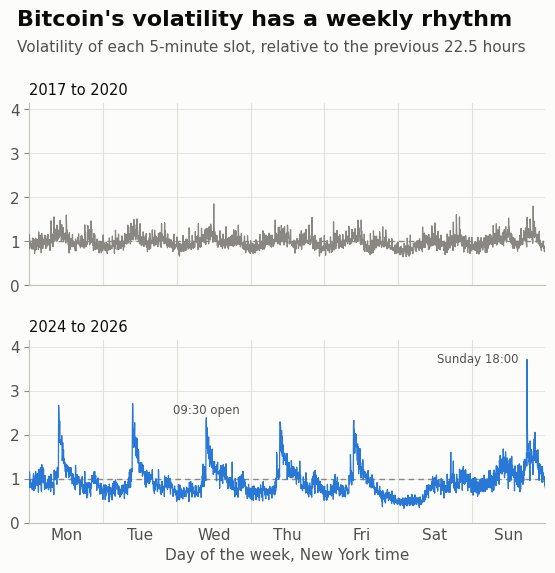

In [3]:
TZ = "America/New_York"
BREAKS = ["2021-01-01", "2024-01-01"]
N_SLOTS = 7 * PER_DAY

slot = se.week_slot(r.index, MINUTES, TZ)
factor, tables = se.seasonal_factor(r / raw["s"], slot, N_SLOTS, BREAKS)

early, late = tables["2017-08-17"]["wsd"].to_numpy(), tables["2024-01-01"]["wsd"].to_numpy()
open_slot = 9 * 12 + 6                       # 09:30 New York
sunday_18 = 6 * PER_DAY + 18 * 12            # Sunday 18:00 New York
fig = jp.week_panels(
    [{"name": "2017 to 2020", "y": early, "color": jp.MUTED},
     {"name": "2024 to 2026", "y": late, "color": jp.BLUE}],
    MINUTES,
    title="Bitcoin's volatility has a weekly rhythm",
    subtitle="Volatility of each 5-minute slot, relative to the previous 22.5 hours",
    xlabel="Day of the week, New York time",
    notes=[{"panel": 1, "x": 2 * PER_DAY + open_slot, "y": late[2 * PER_DAY + open_slot], "text": "09:30 open"},
           {"panel": 1, "x": sunday_18, "y": late[sunday_18], "text": "Sunday 18:00", "ha": "right", "offset": (-6, -4)}],
)
jp.save(fig, "02_weekly_seasonality");

In [4]:
rows = {}
for key, name in [("2017-08-17", "2017 to 2020"), ("2021-01-01", "2021 to 2023"), ("2024-01-01", "2024 to 2026")]:
    f = tables[key]["wsd"].to_numpy().reshape(7, PER_DAY)
    rows[name] = {
        "09:30 open, weekdays": f[:5, open_slot].mean(),
        "08:30, weekdays": f[:5, 8 * 12 + 6].mean(),
        "03:00 to 08:00, weekdays": np.sqrt((f[:5, 36:96] ** 2).mean()),
        "Saturday, whole day": np.sqrt((f[5] ** 2).mean()),
        "Sunday 18:00": f[6, 18 * 12],
        "quietest slot of the week": f.min(),
    }
pd.DataFrame(rows).round(2).rename_axis("Seasonality factor (New York time)")

,2017 to 2020,2021 to 2023,2024 to 2026
Seasonality factor (New York time),,,
"09:30 open, weekdays",1.23,1.71,2.28
"08:30, weekdays",1.13,1.50,1.34
"03:00 to 08:00, weekdays",0.98,0.90,0.80
"Saturday, whole day",0.95,0.86,0.78
Sunday 18:00,1.54,2.48,3.71
quietest slot of the week,0.64,0.50,0.32


The rhythm has sharpened. In 2017-2020 the 09:30 New York slot ran at about 1.2 times the level of the previous 22.5 hours. In 2024-2026 it runs at 2.3 times. The quietest slot of the week, early on Saturday, went from 0.64 to 0.32. Bitcoin has become a US-hours asset.

The largest factor of the week is not a weekday open. It is Sunday 18:00 in New York, at 3.7, the time at which CME futures reopened after the weekend for most of the sample. Part of that reading comes from the window behind it, which on a Sunday evening is a quiet weekend, since the factor is measured against the previous 22.5 hours.

A test that assumes flat volatility is off by a factor of two at the open and by a factor of three in the dead of the weekend. In units of the threshold, that is the difference between a 2-sigma move and a 4-sigma one.

## 3. Before and after

Standard test: 6,461 jumps.  After the correction: 6,341.
Flagged by both: 4,709.  Removed: 1,752 (27% of the standard test's).  Added: 1,632.


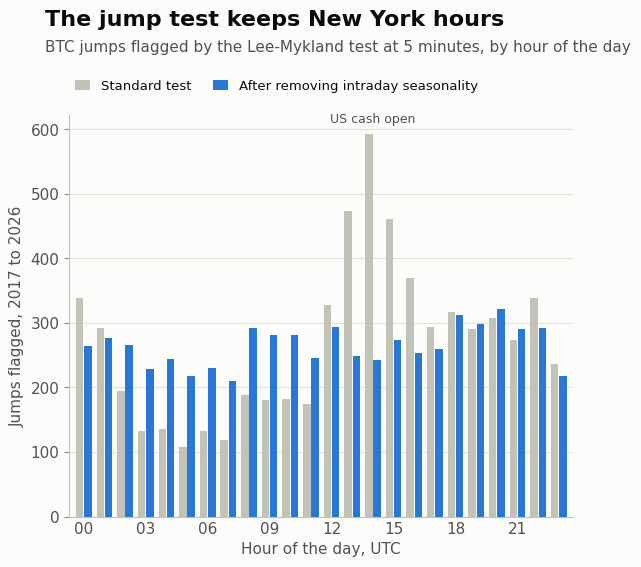

In [5]:
filtered = se.lee_mykland(r, K, PER_DAY, ALPHA, factor=factor)

kept = int((raw["jump"] & filtered["jump"]).sum())
removed = int((raw["jump"] & ~filtered["jump"]).sum())
added = int((~raw["jump"] & filtered["jump"]).sum())
print(f"Standard test: {int(raw['jump'].sum()):,} jumps.  After the correction: {int(filtered['jump'].sum()):,}.")
print(f"Flagged by both: {kept:,}.  Removed: {removed:,} ({100 * removed / raw['jump'].sum():.0f}% of the standard test's).  "
      f"Added: {added:,}.")

hour_utc = (r.index - pd.Timedelta(minutes=MINUTES)).hour
by_hour = pd.DataFrame({"Standard test": raw["jump"].groupby(hour_utc).sum(),
                        "After correction": filtered["jump"].groupby(hour_utc).sum()})
fig = jp.before_after_bars(
    by_hour["Standard test"], by_hour["After correction"], [f"{h:02d}" for h in range(24)],
    title="The jump test keeps New York hours",
    subtitle="BTC jumps flagged by the Lee-Mykland test at 5 minutes, by hour of the day",
    before_name="Standard test", after_name="After removing intraday seasonality",
    xlabel="Hour of the day, UTC", ylabel="Jumps flagged, 2017 to 2026",
    notes=[{"x": 14, "y": by_hour["Standard test"][14], "text": "US cash open"}],
)
jp.save(fig, "02_jumps_by_hour");

In [6]:
by_hour["Change"] = by_hour["After correction"] - by_hour["Standard test"]
print(f"Busiest hour / quietest hour: {by_hour['Standard test'].max() / by_hour['Standard test'].min():.1f} "
      f"before, {by_hour['After correction'].max() / by_hour['After correction'].min():.1f} after")
us = slice(13, 16)
print(f"Share of all jumps flagged between 13:00 and 17:00 UTC: "
      f"{100 * by_hour['Standard test'].loc[us].sum() / by_hour['Standard test'].sum():.0f}% before, "
      f"{100 * by_hour['After correction'].loc[us].sum() / by_hour['After correction'].sum():.0f}% after "
      f"(4 hours out of 24 is 17%)")
by_hour.T.rename_axis("Hour, UTC", axis=1)

Busiest hour / quietest hour: 5.5 before, 1.5 after
Share of all jumps flagged between 13:00 and 17:00 UTC: 29% before, 16% after (4 hours out of 24 is 17%)


"Hour, UTC",0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Standard test,339,292,194,132,135,108,133,119,188,181,182,174,328,474,593,461,370,293,317,291,308,274,338,237
After correction,264,276,265,229,244,218,230,210,292,281,282,245,294,249,243,273,253,260,313,298,322,290,292,218
Change,-75,-16,71,97,109,110,97,91,104,100,100,71,-34,-225,-350,-188,-117,-33,-4,7,14,16,-46,-19


The standard test puts 29% of its jumps in the four hours around the US open. After the correction that share is 16%, which is what four hours out of twenty-four should get if jumps did not care about the clock.

The correction is not a discount. It moves detections: 1,752 leave, mostly from US hours, and 1,632 arrive, mostly between 02:00 and 12:00 UTC. The moves that leave are ordinary for their hour. The moves that arrive are small in absolute terms and extraordinary for theirs.

## 4. What it removes, and what it leaves

The handover for this post listed hypotheses. Here is how each one fares.

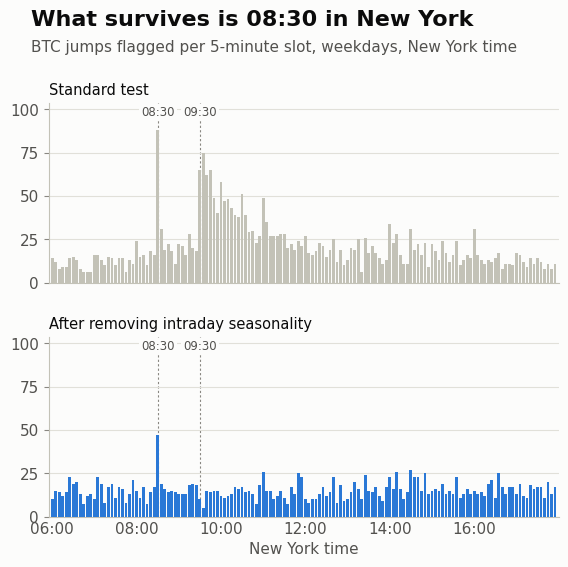

In [7]:
start_ny = (r.index - pd.Timedelta(minutes=MINUTES)).tz_convert(TZ)
weekday = np.asarray(start_ny.dayofweek < 5)
slot_of_day = np.asarray((start_ny.hour * 60 + start_ny.minute) // MINUTES)

def per_slot(jump, mask):
    return jump[mask].groupby(slot_of_day[mask]).sum().reindex(range(PER_DAY), fill_value=0).to_numpy()

before_ny, after_ny = per_slot(raw["jump"], weekday), per_slot(filtered["jump"], weekday)
lo, hi = 6 * 12, 18 * 12                     # 06:00 to 18:00 New York
labels = [f"{s // 12:02d}:{(s % 12) * 5:02d}" for s in range(lo, hi)]
fig = jp.slot_panels(
    [{"name": "Standard test", "y": before_ny[lo:hi], "color": jp.AXIS},
     {"name": "After removing intraday seasonality", "y": after_ny[lo:hi], "color": jp.BLUE}],
    labels,
    title="What survives is 08:30 in New York",
    subtitle="BTC jumps flagged per 5-minute slot, weekdays, New York time",
    marks=[{"slot": labels.index("08:30"), "text": "08:30"}, {"slot": labels.index("09:30"), "text": "09:30"}],
    tick_every=24, xlabel="New York time",
)
jp.save(fig, "02_new_york_slots");

In [8]:
def count_at(jump, label, clock):
    start = (r.index - pd.Timedelta(minutes=MINUTES)).tz_convert(clock)
    mask = np.asarray(start.strftime("%H:%M") == label)
    if clock == TZ:
        mask &= weekday
    return int(jump[mask].sum())

checks = [("US data releases, 08:30 New York, weekdays", "08:30", TZ),
          ("US cash open, 09:30 New York, weekdays", "09:30", TZ),
          ("Five minutes after the open, 09:35", "09:35", TZ),
          ("Funding timestamp, 00:00 UTC", "00:00", "UTC"),
          ("Funding timestamp, 08:00 UTC", "08:00", "UTC"),
          ("Funding timestamp, 16:00 UTC", "16:00", "UTC")]
slots = pd.DataFrame(
    {"Standard test": [count_at(raw["jump"], lab, tz) for _, lab, tz in checks],
     "After correction": [count_at(filtered["jump"], lab, tz) for _, lab, tz in checks]},
    index=[name for name, _, _ in checks])
slots.loc["Median weekday slot, New York clock"] = [np.median(before_ny), np.median(after_ny)]
utc_label = (r.index - pd.Timedelta(minutes=MINUTES)).strftime("%H:%M")
slots.loc["Median slot, UTC clock, all days"] = [raw["jump"].groupby(utc_label).sum().median(),
                                               filtered["jump"].groupby(utc_label).sum().median()]
display(slots.astype(int))

dow = np.asarray(start_ny.dayofweek)
per_day = pd.DataFrame({name: d["jump"].groupby(dow).sum() / (d["J"].notna().groupby(dow).sum() / PER_DAY)
                        for name, d in [("Standard test", raw), ("After correction", filtered)]})
per_day.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
per_day.T.round(2).rename_axis("Jumps flagged per day")

,Standard test,After correction
"US data releases, 08:30 New York, weekdays",88,47
"US cash open, 09:30 New York, weekdays",65,10
"Five minutes after the open, 09:35",75,5
"Funding timestamp, 00:00 UTC",43,19
"Funding timestamp, 08:00 UTC",16,20
"Funding timestamp, 16:00 UTC",48,26
"Median weekday slot, New York clock",12,14
"Median slot, UTC clock, all days",20,22


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
Jumps flagged per day,,,,,,,
Standard test,2.17,1.66,2.02,1.76,1.57,1.36,3.07
After correction,1.95,1.58,1.91,1.78,1.71,2.13,2.30


- **The US cash open is an artefact.** The 09:30 slot collects 65 jumps under the standard test and 10 after the correction, below the median slot. The whole 09:30 to 11:00 hump is gone.
- **US data releases are not.** The 08:30 slot goes from 88 to 47 and remains the tallest of the day, at more than three times the median slot. The robust estimator sees a slot that is calm on most days and violent on a few, keeps the factor low, and the release-day jumps stay flagged. A time-of-day cluster is not all artefact.
- **Funding timestamps are mostly the clock.** Under the standard test 00:00 and 16:00 UTC look special, with 43 and 48 jumps against a median slot of 20. After the correction they have 19 and 26 against a median of 22. The 08:00 timestamp never stood out.
- **The weekend is where the standard test fails both ways.** It flags 1.4 jumps on an average Saturday and 3.1 on an average Sunday. On Saturday the window behind each return is still full of Friday. On Sunday it is full of Saturday. After the correction the two days look alike, at 2.1 and 2.3.

## 5. Robustness, and the number that did not move

In [9]:
def run(symbol, tz=TZ, breaks=BREAKS, estimator="wsd"):
    x = returns[symbol]
    base = se.lee_mykland(x, K, PER_DAY, ALPHA)
    f, _ = se.seasonal_factor(x / base["s"], se.week_slot(x.index, MINUTES, tz), N_SLOTS, breaks, estimator)
    corr = se.lee_mykland(x, K, PER_DAY, ALPHA, factor=f)
    hours = (x.index - pd.Timedelta(minutes=MINUTES)).hour
    spread = lambda j: j.groupby(hours).sum().max() / j.groupby(hours).sum().min()   # noqa: E731
    ny = (x.index - pd.Timedelta(minutes=MINUTES)).tz_convert(TZ)
    at_0830 = np.asarray((ny.strftime("%H:%M") == "08:30") & (ny.dayofweek < 5))
    return {"Standard test": int(base["jump"].sum()), "After correction": int(corr["jump"].sum()),
            "Removed": int((base["jump"] & ~corr["jump"]).sum()), "Added": int((~base["jump"] & corr["jump"]).sum()),
            "Hourly spread before": round(spread(base["jump"]), 1), "Hourly spread after": round(spread(corr["jump"]), 1),
            "08:30 NY after": int(corr["jump"][at_0830].sum())}

variants = {
    "BTC, as above": run("BTCUSDT"),
    "BTC, slots on the UTC clock": run("BTCUSDT", tz="UTC"),
    "BTC, one factor for the whole sample": run("BTCUSDT", breaks=None),
    "BTC, non-robust factor (standard deviation)": run("BTCUSDT", estimator="sd"),
    "ETH, as above": run("ETHUSDT"),
}
table = pd.DataFrame(variants).T
int_cols = ["Standard test", "After correction", "Removed", "Added", "08:30 NY after"]
table[int_cols] = table[int_cols].astype(int)
table

,Standard test,After correction,Removed,Added,Hourly spread before,Hourly spread after,08:30 NY after
"BTC, as above",6461,6341,1752,1632,5.5,1.5,47
"BTC, slots on the UTC clock",6461,6293,1768,1600,5.5,1.5,54
"BTC, one factor for the whole sample",6461,6086,1713,1338,5.5,1.5,49
"BTC, non-robust factor (standard deviation)",6461,6466,1957,1962,5.5,1.5,30
"ETH, as above",6276,6237,1595,1556,5.1,1.6,42


The picture holds on the UTC clock, with a single factor for the whole sample, and on ETH.

The fourth row shows why the estimator has to be robust. With a plain standard deviation, the release-day jumps at 08:30 inflate that slot's own factor, and the count there falls from 47 to 30. A third of them hide behind themselves.

Now the number that did not move. With no jumps, the test should flag about 33 returns in nine years. It flags 6,461 before the correction and 6,341 after. Seasonality decides the hour; it does not decide the count. Whatever produces two detections a day, it is not the clock.

Post 1 offered one candidate: volatility that moves inside the window, in bursts of minutes, which no 22.5-hour average can follow. Post 3 looks at what the price itself is made of at trade level. Post 4 asks whether "jump" is even one thing.

One more fact for later: nearly half of the BTC detections coincide with an ETH detection in the same five minutes. Whatever these are, they are market-wide.

In [10]:
btc_j = filtered["jump"]
eth_base = se.lee_mykland(returns["ETHUSDT"], K, PER_DAY, ALPHA)
eth_f, _ = se.seasonal_factor(returns["ETHUSDT"] / eth_base["s"],
                              se.week_slot(returns["ETHUSDT"].index, MINUTES, TZ), N_SLOTS, BREAKS)
eth_j = se.lee_mykland(returns["ETHUSDT"], K, PER_DAY, ALPHA, factor=eth_f)["jump"]
common = btc_j.index.intersection(eth_j.index)
together = int((btc_j.loc[common] & eth_j.loc[common]).sum())
print(f"After the correction, {together:,} of {int(btc_j.sum()):,} BTC detections "
      f"({100 * together / btc_j.sum():.0f}%) coincide with an ETH detection in the same 5-minute interval.")

After the correction, 2,984 of 6,341 BTC detections (47%) coincide with an ETH detection in the same 5-minute interval.


## 6. Caveats

- **Scheduled news produces genuine jumps at fixed hours.** The 08:30 slot shows it. A cluster by time of day is a mix of artefact and news, and only a robust seasonality estimate separates them.
- **Daylight saving.** US-driven effects sit at fixed New York times and move by an hour in UTC. The factor is estimated on the New York clock for that reason. Effects tied to UTC, such as funding, are then smeared by an hour for part of the year. The UTC-clock variant above gives the same picture.
- **The factor is estimated in-sample**, on three sub-periods chosen by eye from the drift in the pattern. With about 150 to 180 weeks per period, each slot's factor carries an estimation error of several percent.
- **Many returns are tested.** The 1% level is per day, not per return. That is 33 expected false alarms in the sample, against more than 6,000 detections.
- **Five-minute bars.** A detection is a 5-minute return that is too large for its local volatility. Post 1 showed what the largest such moves look like inside: mostly slides, not gaps. The test cannot tell the difference.
- **The window is still 22.5 hours.** The correction removes the predictable part of intraday volatility. The unpredictable part, bursts, is untouched.

## 7. Takeaways

1. Bitcoin's volatility has a weekly rhythm, and it has sharpened: the 09:30 New York slot went from 1.2 to 2.3 times the daily level between 2017-2020 and 2024-2026.
2. A jump test that ignores the rhythm flags the US session and misses the quiet hours. A quarter of its detections are the clock.
3. Correcting for it moves the detections without changing their number. The busy-hour excess is replaced by quiet-hour jumps the standard test could not see.
4. What survives is 08:30 in New York. Real news at a fixed time looks like seasonality, and only a robust estimator keeps the two apart.
5. The test still fires about 190 times more often than its nominal size. Seasonality is not why.

## Equation images for the post

In [11]:
jp.render_equation(r"L(i)=\dfrac{r_i}{\hat{\sigma}_i},\qquad \hat{\sigma}_i^{\,2}=\dfrac{1}{K-2}\sum_{j=i-K+2}^{i-1}|r_j|\,|r_{j-1}|",
                   "02_eq_test", "Lee-Mykland: each return against the bipower volatility of the K before it", fontsize=20)
jp.render_equation(r"FJ_i=\dfrac{|r_i|}{\hat{f}_i\ s_i},\qquad \mathrm{mean\ of}\ \hat{f}^{\,2}\ \mathrm{over\ the\ week}=1",
                   "02_eq_filtered", "The same test after dividing by the seasonality factor of the slot", fontsize=20);

## References

- Lee, S. S. and Mykland, P. A. (2008). Jumps in financial markets: A new nonparametric test and jump dynamics. *Review of Financial Studies*, 21(6), 2535-2563. [doi:10.1093/rfs/hhm056](https://doi.org/10.1093/rfs/hhm056) · [author copy](https://galton.uchicago.edu/~mykland/paperlinks/LeeMykland-2535.pdf)
- Boudt, K., Croux, C. and Laurent, S. (2011). Robust estimation of intraweek periodicity in volatility and jump detection. *Journal of Empirical Finance*, 18(2), 353-367. [doi:10.1016/j.jempfin.2010.11.005](https://doi.org/10.1016/j.jempfin.2010.11.005) · [working paper](https://lirias.kuleuven.be/handle/123456789/203659)

The formulas and constants above were checked against the author copy of the first paper and the KU Leuven working-paper version of the second.

---

*Code, data loaders and figures: [github.com/PascalLemieux/jumps](https://github.com/PascalLemieux/jumps). Comments and corrections welcome on [LinkedIn](https://linkedin.com/in/pascal-lemieux).*